In [8]:
# 新建一个数据集为train.txt与val.txt以及test.txt，比例为75% + 15% + 10%
# 数据为 cos曲线 与 sin曲线 特征离散点
# 格式为 x值 y值 曲线类别 json 格式

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import random    
import json
import os

In [10]:

# 生成数据
def generate_data(num_points, curve_type):
    x_values = np.linspace(0, 2 * np.pi, num_points)
    if curve_type == 'cos':
        y_values = np.cos(x_values).astype(np.float32)
        y_values += 0.1 * np.random.randn(*y_values.shape)

    elif curve_type == 'sin':
        y_values = np.sin(x_values).astype(np.float32)
        y_values += 0.1 * np.random.randn(*y_values.shape)
        
    else:
        raise ValueError("curve_type must be 'cos' or 'sin'")
    
    data = [{"x": float(x), "y": float(y), "curve": curve_type} for x, y in zip(x_values, y_values)]
    return data


In [11]:
# 绘制数据集的图表
def plot_data(data):
    cos_x = [item['x'] for item in data if item['curve'] == 'cos']
    cos_y = [item['y'] for item in data if item['curve'] == 'cos']
    
    sin_x = [item['x'] for item in data if item['curve'] == 'sin']
    sin_y = [item['y'] for item in data if item['curve'] == 'sin']
    
    plt.figure(figsize=(12, 6))
    plt.plot(cos_x, cos_y, label='cos', color='blue', marker='o', linestyle='')
    plt.plot(sin_x, sin_y, label='sin', color='red', marker='x', linestyle='')
    plt.title('Cosine and Sine Curves')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True)
    plt.show()


In [12]:
# 划分训练集和验证集以及测试集，比例为75% + 15% + 10%
def split_data(data, train_ratio=0.80, val_ratio=0.15, test_ratio=0.05):
    total_length = len(data)
    train_end = int(total_length * train_ratio)
    val_end = train_end + int(total_length * val_ratio)
    
    train_data = data[:train_end]
    val_data = data[train_end:val_end]
    test_data = data[val_end:]
    
    return train_data, val_data, test_data

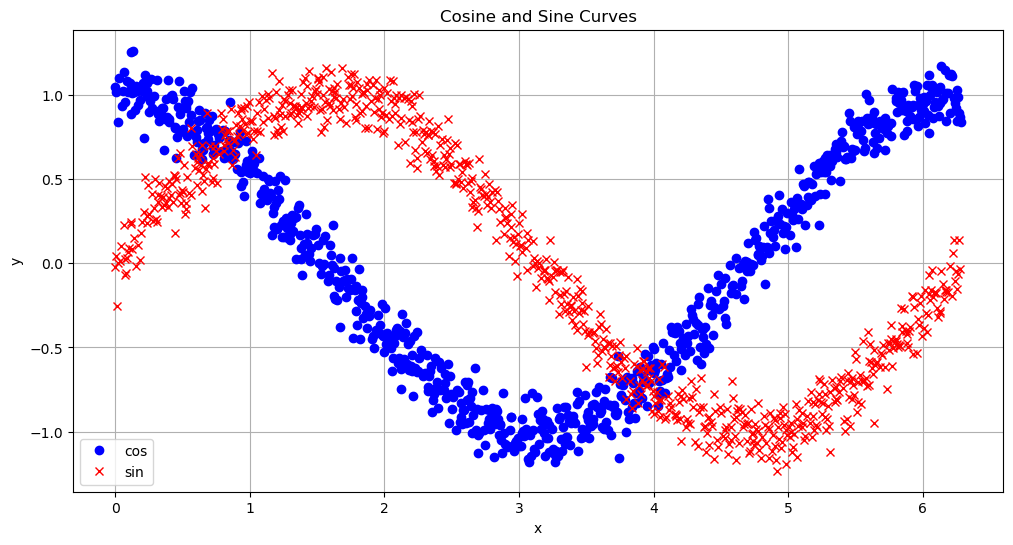

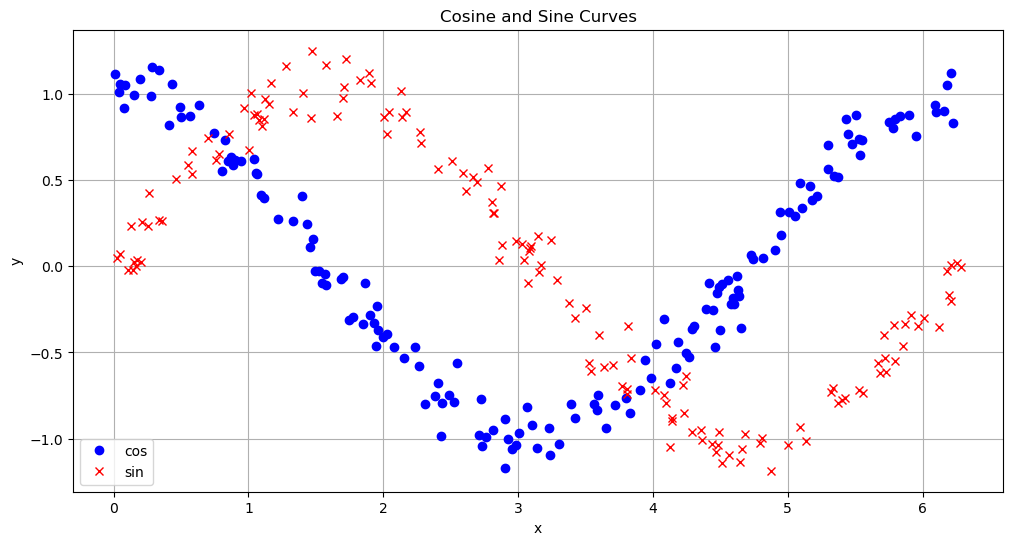

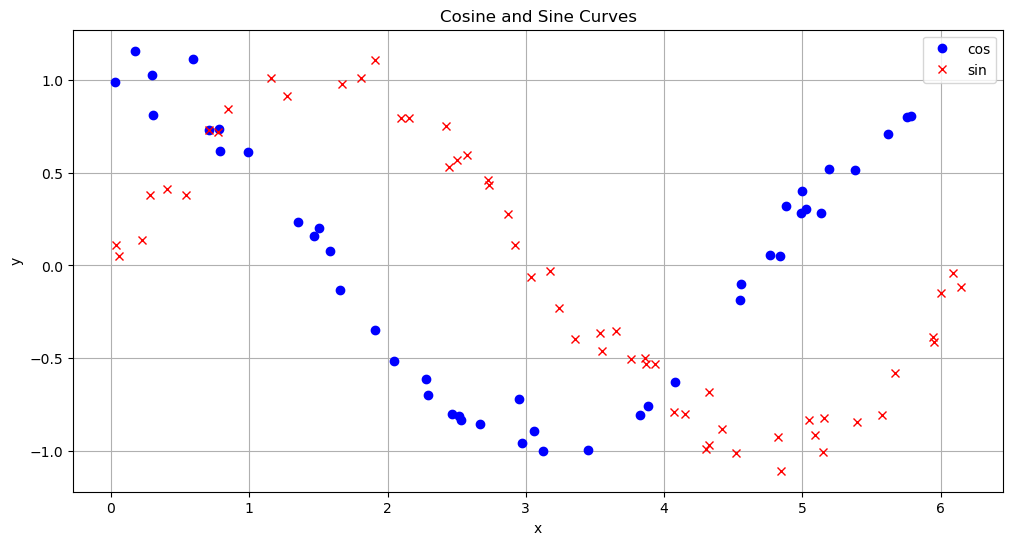

In [13]:
# 生成 cos 和 sin 曲线的数据
num_points_per_curve = 1000
cos_data = generate_data(num_points_per_curve, 'cos')
sin_data = generate_data(num_points_per_curve, 'sin')

# 合并数据并打乱
all_data = cos_data + sin_data
random.shuffle(all_data)

# 划分训练集、验证集和测试集，比例为75% + 15% + 10%
train_data, val_data, test_data = split_data(all_data)

# 绘制训练集和验证集的图表
plot_data(train_data)
plot_data(val_data)
plot_data(test_data)


In [14]:
# 保存为 JSON 文件
if not os.path.isdir("./data"):
    os.makedirs("./data")

with open('./data/train.txt', 'w') as f:
    json.dump(train_data, f)

with open('./data/val.txt', 'w') as f:
    json.dump(val_data, f)

with open('./data/test.txt', 'w') as f:
    json.dump(test_data, f)